# Jour 3 — Clustering hiérarchique et par densité

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**

**Objectifs du jour (Chapitres 3.2 et 3.3)**

| Partie | Contenu |
|---|---|
| A | Classification ascendante hiérarchique (CAH) : liens *single*, *complete*, *average*, *Ward* ; dendrogrammes ; choix de la coupure |
| B | DBSCAN : réglage de ε et `min_samples` par le graphique des k-distances ; points cœur, bordure, bruit |
| C | Limites de K-means face à DBSCAN |

> Ce notebook fait partie d'une série de huit (un par étape du projet). Les huit sont aussi réunis, dans l'ordre, dans `projet_complet.ipynb`.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from src.config import SEED, FIG, TAB, LAB, OUT, GOWER_CACHE
from src import preprocessing as pp
from src.clustering_utils import gower_matrix, knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

d = pp.prepare_all()
X_a, X_mixed, y, illus = d["X_a"], d["X_mixed"], d["y"], d["illus"]
D_gow = gower_matrix(X_mixed, cache=GOWER_CACHE)
emb = np.load(OUT / "embeddings_sample.npz")
n = len(X_a)
partitions = pd.DataFrame(index=X_a.index)
print("Échantillon :", X_a.shape)

Échantillon : (4000, 37)


# Partie A — Classification ascendante hiérarchique (CAH)

**Principe.** Au départ, chaque client est un cluster. À chaque étape, on fusionne les deux clusters les plus proches, jusqu'à n'en avoir plus qu'un. L'historique des fusions forme un arbre : le **dendrogramme**. On n'a pas à fixer $k$ à l'avance : on **coupe** l'arbre à la hauteur voulue.

Tout dépend de la définition de la distance entre deux **clusters** $A$ et $B$ (le *lien*) :

| Lien | Distance entre A et B | Comportement attendu |
|---|---|---|
| *single* (saut minimal) | plus petite distance entre un point de A et un point de B | effet de **chaîne** : clusters allongés, points isolés |
| *complete* (saut maximal) | plus grande distance entre un point de A et un point de B | clusters compacts, sensible aux extrêmes |
| *average* (moyen) | moyenne de toutes les distances entre A et B | compromis |
| *Ward* | augmentation d'inertie intra-classe causée par la fusion | clusters sphériques de tailles voisines (même critère que K-means) |

Les quatre liens sont appliqués à la distance euclidienne sur la représentation (a) : le lien de Ward **exige** une distance euclidienne.

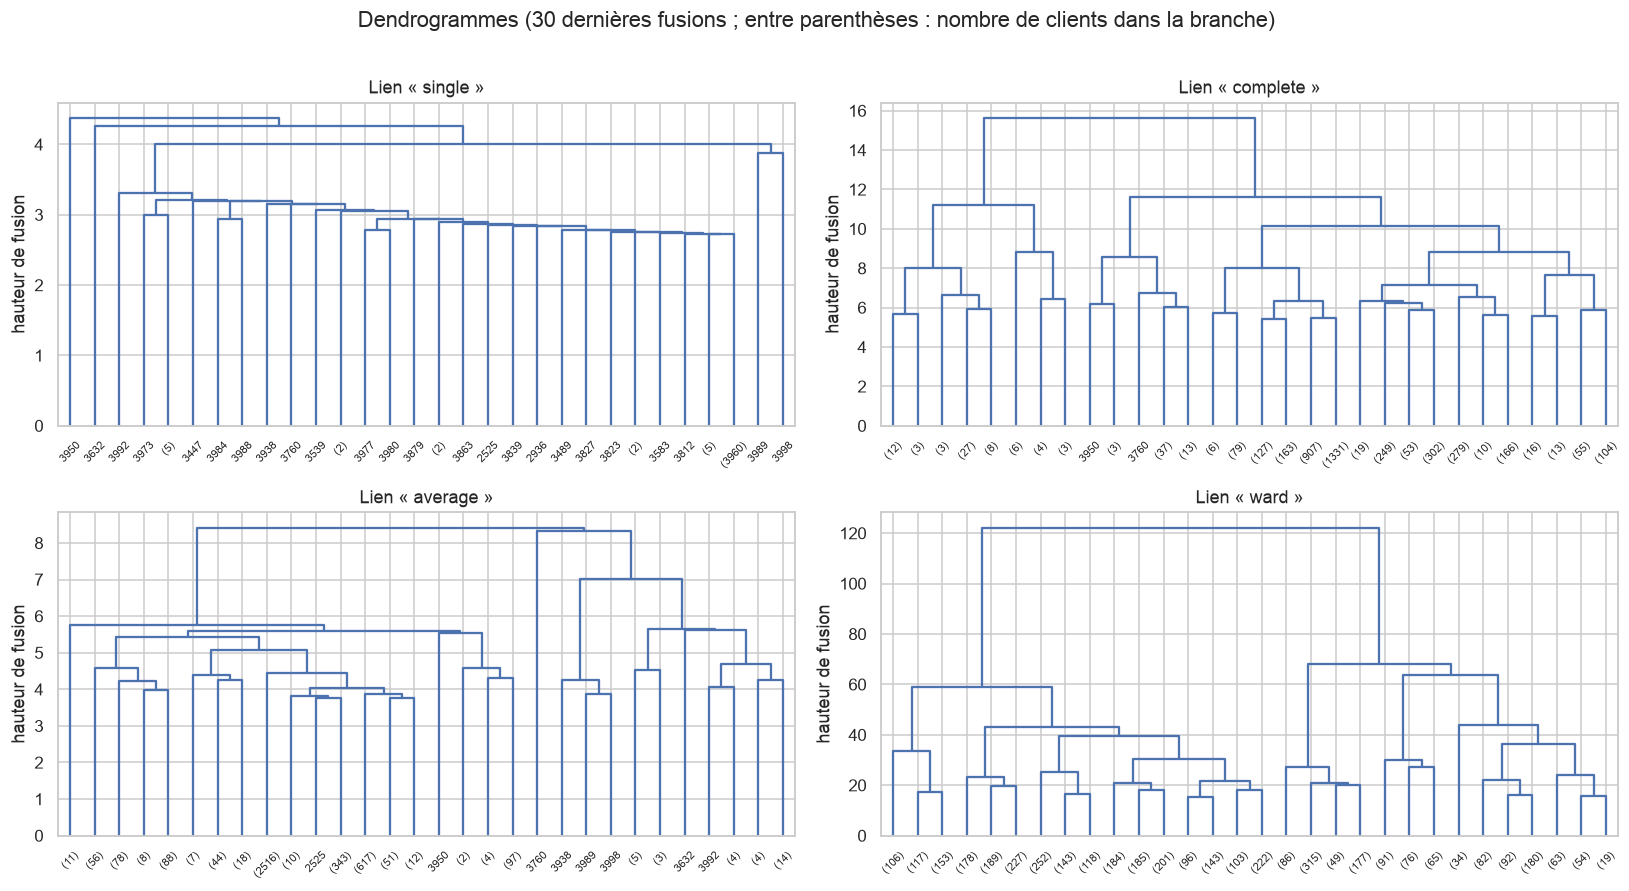

In [3]:
D_euc_cond = pdist(X_a.values, metric="euclidean")      # forme « condensée » attendue par scipy
links = {m: linkage(D_euc_cond, method=m) for m in ["single", "complete", "average"]}
links["ward"] = linkage(X_a.values, method="ward")

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (m, Zl) in zip(axes.ravel(), links.items()):
    dendrogram(Zl, truncate_mode="lastp", p=30, ax=ax, no_labels=False, leaf_font_size=7,
               color_threshold=0, above_threshold_color="#4C72B0")
    ax.set_title(f"Lien « {m} »"); ax.set_ylabel("hauteur de fusion")
plt.suptitle("Dendrogrammes (30 dernières fusions ; entre parenthèses : nombre de clients dans la branche)", y=1.01)
plt.tight_layout(); plt.savefig(FIG / "03_dendrogrammes.png", bbox_inches="tight"); plt.show()

In [4]:
# Que donne chaque lien si on coupe à 3 ou 4 clusters ?
rows = []
for m, Zl in links.items():
    coph, _ = cophenet(Zl, D_euc_cond)
    for k in [3, 4]:
        lab = fcluster(Zl, t=k, criterion="maxclust") - 1
        sizes = sorted(np.bincount(lab), reverse=True)
        rows.append({"lien": m, "k": k, "tailles des clusters": " / ".join(map(str, sizes)),
                     "plus petit cluster (%)": round(100 * sizes[-1] / n, 2),
                     "silhouette": round(silhouette_score(X_a, lab), 3),
                     "corrélation cophénétique": round(coph, 3)})
cah_tab = pd.DataFrame(rows)
cah_tab.to_csv(TAB / "03_comparatif_liens.csv", index=False)
cah_tab

,lien,k,tailles des clusters,plus petit cluster (%),silhouette,corrélation cophénétique
0,single,3,3998 / 1 / 1,0.02,0.423,0.698
1,single,4,3996 / 2 / 1 / 1,0.02,0.424,0.698
2,complete,3,3879 / 66 / 55,1.38,0.316,0.745
3,complete,4,3879 / 55 / 53 / 13,0.32,0.305,0.745
4,average,3,3964 / 35 / 1,0.02,0.489,0.829
5,average,4,3964 / 32 / 3 / 1,0.02,0.469,0.829
6,ward,3,2617 / 756 / 627,15.68,0.193,0.579
7,ward,4,2617 / 627 / 524 / 232,5.80,0.213,0.579


**Lecture des dendrogrammes et du tableau :**
- ***single*** : effet de chaîne caricatural. L'arbre « en escalier » détache les clients un par un : on obtient un cluster géant et des singletons. Inutilisable pour une segmentation.
- ***average*** et ***complete*** : un cluster rassemble plus de 95 % des clients, les autres sont minuscules. Ces liens isolent des **clients atypiques** plutôt qu'ils ne segmentent.
- ***Ward*** : le seul lien qui produit des groupes **équilibrés** et exploitables.

**Piège à retenir.** Les liens *single*, *average* et *complete* affichent ici les **meilleures silhouettes**, alors que leurs partitions sont sans intérêt. Isoler une poignée de points très éloignés suffit à obtenir une silhouette élevée. Un indice de qualité ne se lit donc jamais sans regarder la **taille des clusters**. On s'en souviendra au Jour 4.

La corrélation cophénétique mesure la fidélité de l'arbre aux distances d'origine ; elle est plus faible pour Ward, car ce lien déforme volontairement les distances pour équilibrer les groupes. Ce n'est pas un critère de qualité de la partition.

## A.2 Choix de la coupure (lien de Ward)
On coupe là où les fusions deviennent « coûteuses » : un **grand saut** de hauteur entre deux fusions successives signifie qu'on est en train de réunir deux groupes réellement différents.

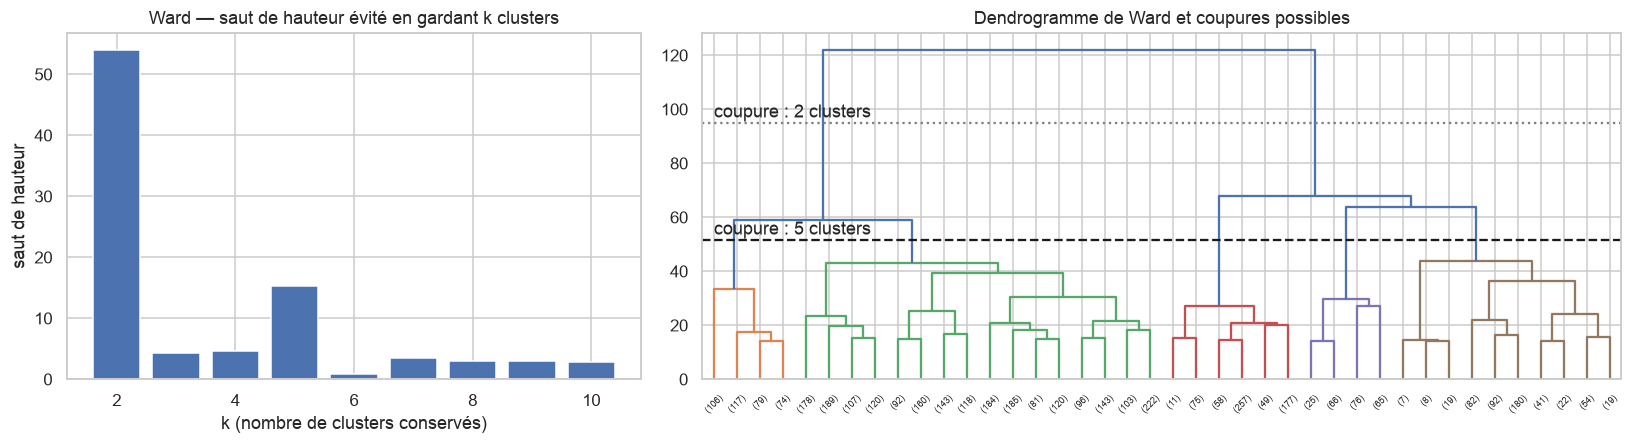

,nombre de clusters avant fusion,hauteur de fusion,saut par rapport à la fusion suivante
0,2,122.10,54.05
1,3,68.04,4.24
2,4,63.81,4.67
3,5,59.14,15.21
4,6,43.93,0.90
5,7,43.03,3.55
6,8,39.48,3.02
7,9,36.46,3.03
8,10,33.42,2.87


In [5]:
Zw = links["ward"]
last = Zw[-10:, 2][::-1]                   # hauteurs des 10 dernières fusions (de la dernière à la 10e)
jumps = pd.DataFrame({"nombre de clusters avant fusion": range(2, 12), "hauteur de fusion": last})
jumps["saut par rapport à la fusion suivante"] = jumps["hauteur de fusion"].diff(-1)
jumps = jumps.iloc[:9]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(jumps.iloc[:, 0], jumps.iloc[:, 2], color="#4C72B0")
axes[0].set_xlabel("k (nombre de clusters conservés)"); axes[0].set_ylabel("saut de hauteur")
axes[0].set_title("Ward — saut de hauteur évité en gardant k clusters")
cut5 = (Zw[-5, 2] + Zw[-4, 2]) / 2          # entre la fusion 6->5 et la fusion 5->4
dendrogram(Zw, truncate_mode="lastp", p=40, ax=axes[1], leaf_font_size=6, color_threshold=cut5)
axes[1].axhline(cut5, ls="--", color="k"); axes[1].text(5, cut5 * 1.04, "coupure : 5 clusters")
cut2 = (Zw[-2, 2] + Zw[-1, 2]) / 2
axes[1].axhline(cut2, ls=":", color="grey"); axes[1].text(5, cut2 * 1.02, "coupure : 2 clusters")
axes[1].set_title("Dendrogramme de Ward et coupures possibles")
plt.tight_layout(); plt.savefig(FIG / "03_ward_coupure.png", bbox_inches="tight"); plt.show()
jumps.round(2)

In [6]:
ward_rows = []
for k in range(2, 7):
    lab = fcluster(Zw, t=k, criterion="maxclust") - 1
    partitions[f"ward_k{k}"] = lab
    ward_rows.append({"k": k, "silhouette": silhouette_score(X_a, lab),
                      "tailles": " / ".join(map(str, sorted(np.bincount(lab), reverse=True)))})
pd.DataFrame(ward_rows).round(3)

,k,silhouette,tailles
0,2,0.234,2617 / 1383
1,3,0.193,2617 / 756 / 627
2,4,0.213,2617 / 627 / 524 / 232
3,5,0.180,2241 / 627 / 524 / 376 / 232
4,6,0.183,2241 / 627 / 490 / 376 / 232 / 34


**Choix de la coupure.** L'arbre propose deux coupures naturelles :
- **k = 2** : de loin le plus grand saut (54). C'est la séparation la plus nette, la même que celle trouvée par K-means.
- **k = 5** : second saut marqué (15). En dessous, les fusions coûtent peu ; passer de 5 à 4 clusters oblige à réunir deux groupes nettement différents.

Entre les deux (k = 3 ou 4), les sauts sont faibles : l'arbre ne distingue pas vraiment ces niveaux. La silhouette, elle, classe k = 2 en tête (0,23), puis **k = 4** (0,21) devant k = 5 (0,18).

→ Le dendrogramme et la silhouette ne désignent pas exactement le même niveau fin. On garde donc toutes les coupures de Ward de **k = 2 à 6** et on tranchera au Jour 4 avec l'ensemble des indices. Propriété utile de la CAH : ces partitions sont **emboîtées**. Le grand groupe de 2 617 clients reste intact de k = 2 à k = 4 ; seul l'autre groupe est subdivisé.

 A.3 CAH sur la distance de Gower
Les liens *average* et *complete* acceptent n'importe quelle dissimilarité. On refait donc la CAH avec Gower, mieux adaptée aux données mixtes.

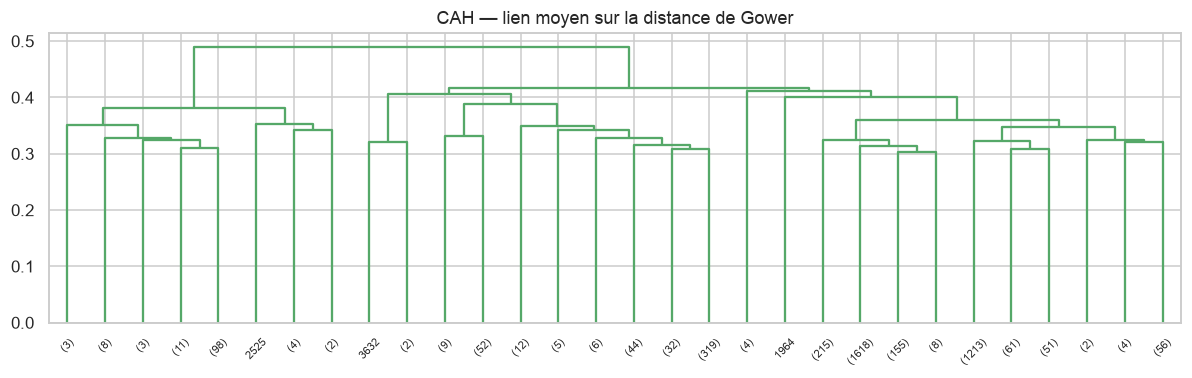

,k,silhouette (Gower),tailles
0,2,0.300,3870 / 130
1,3,0.228,3388 / 482 / 130
2,4,0.162,3384 / 482 / 130 / 4
3,5,0.154,3384 / 479 / 130 / 4 / 3
4,6,0.081,3383 / 479 / 130 / 4 / 3 / 1


In [7]:
D_gow_cond = squareform(D_gow, checks=False)
Zg = linkage(D_gow_cond, method="average")
fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(Zg, truncate_mode="lastp", p=30, ax=ax, leaf_font_size=7, color_threshold=0, above_threshold_color="#55A868")
ax.set_title("CAH — lien moyen sur la distance de Gower")
plt.tight_layout(); plt.savefig(FIG / "03_dendrogramme_gower.png", bbox_inches="tight"); plt.show()

gow_rows = []
for k in range(2, 7):
    lab = fcluster(Zg, t=k, criterion="maxclust") - 1
    partitions[f"cah_gower_k{k}"] = lab
    gow_rows.append({"k": k, "silhouette (Gower)": silhouette_score(D_gow, lab, metric="precomputed"),
                     "tailles": " / ".join(map(str, sorted(np.bincount(lab), reverse=True)))})
pd.DataFrame(gow_rows).round(3)

In [8]:
lab = partitions["cah_gower_k3"]
pd.crosstab(lab, X_mixed["poutcome"]).assign(effectif=np.bincount(lab))

poutcome,failure,nonexistent,success,effectif
cah_gower_k3,,,,
0,1,0,129,130
1,431,51,0,482
2,8,3379,1,3388


**Lecture.** Avec Gower, la CAH isole des groupes définis par l'**historique de contact** : un petit groupe de clients dont la campagne précédente a été un **succès**, un groupe de clients dont elle a été un **échec**, et la grande masse des clients jamais démarchés. Les groupes sont très déséquilibrés, mais ils ont un sens métier clair : ce sont des « niches » plutôt qu'une segmentation de toute la clientèle.

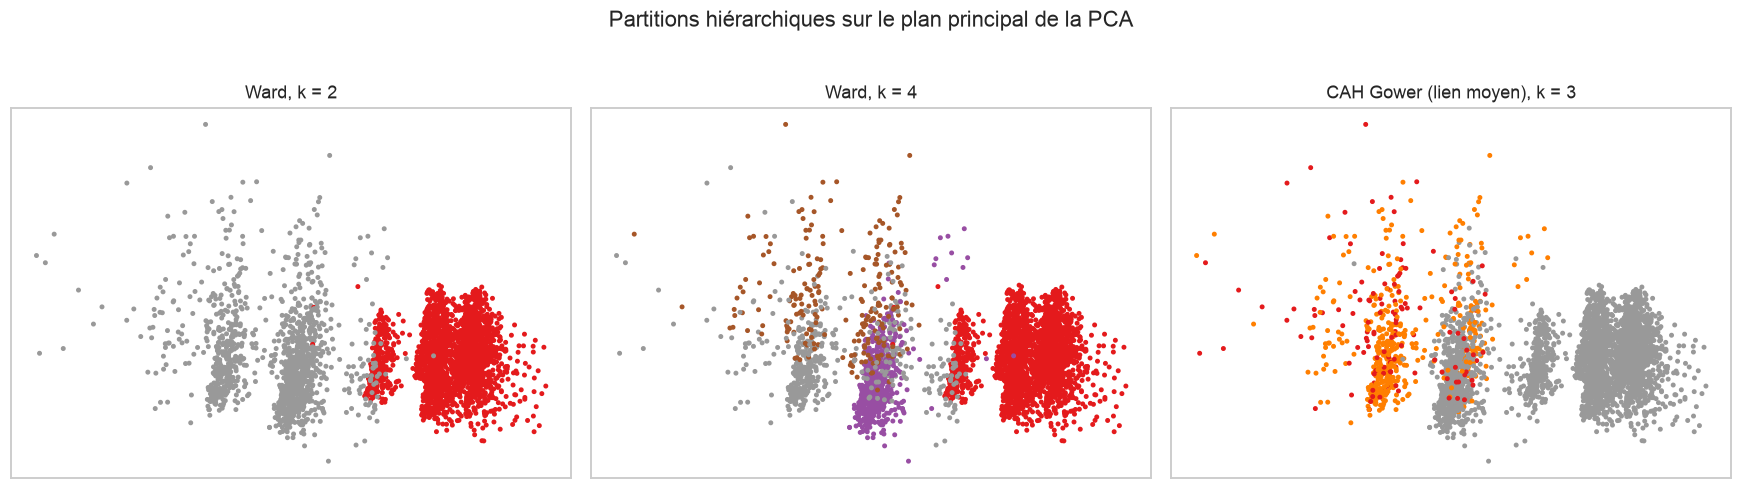

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (col, title) in zip(axes, [("ward_k2", "Ward, k = 2"), ("ward_k4", "Ward, k = 4"), ("cah_gower_k3", "CAH Gower (lien moyen), k = 3")]):
    ax.scatter(emb["pca"][:, 0], emb["pca"][:, 1], c=partitions[col], s=5, cmap="Set1")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Partitions hiérarchiques sur le plan principal de la PCA", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "03_cah_pca.png", bbox_inches="tight"); plt.show()

# Partie B — DBSCAN (clustering par densité)

**Principe.** Un cluster est une zone **dense** de l'espace, séparée des autres par des zones vides. Deux paramètres :
- **ε** (noté $d^*$ dans le cours) : rayon du voisinage ;
- **`min_samples`** (noté $e^*$) : nombre minimal de points dans ce voisinage pour être en zone dense.

Chaque point reçoit un statut :
- **point cœur** : au moins `min_samples` points (lui compris) à distance ≤ ε ;
- **point de bordure** : pas assez de voisins, mais situé dans le voisinage d'un point cœur ;
- **bruit** : ni l'un ni l'autre → il n'appartient à **aucun** cluster (étiquette −1).

Avantages : pas de $k$ à fixer, clusters de forme quelconque, détection des points isolés.

## B.1 Espace de travail
En grande dimension, toutes les distances se ressemblent et la notion de densité perd son sens. On applique donc DBSCAN sur les **5 premières composantes principales**.

In [10]:
pca5 = PCA(n_components=5, random_state=SEED).fit(X_a)
Z5 = pca5.transform(X_a)
print(f"Variance conservée par 5 composantes : {pca5.explained_variance_ratio_.sum():.1%}")

Variance conservée par 5 composantes : 66.1%


## B.2 Réglage des paramètres : graphique des k-distances
- `min_samples` : règle usuelle $2 \times$ dimension, soit **10**.
- ε : pour chaque client, on calcule la distance à son 10ᵉ plus proche voisin, puis on trie ces distances. Les points des zones denses ont une petite k-distance ; les points isolés une grande. Le **coude** de la courbe sépare les deux régimes : c'est la valeur de ε.

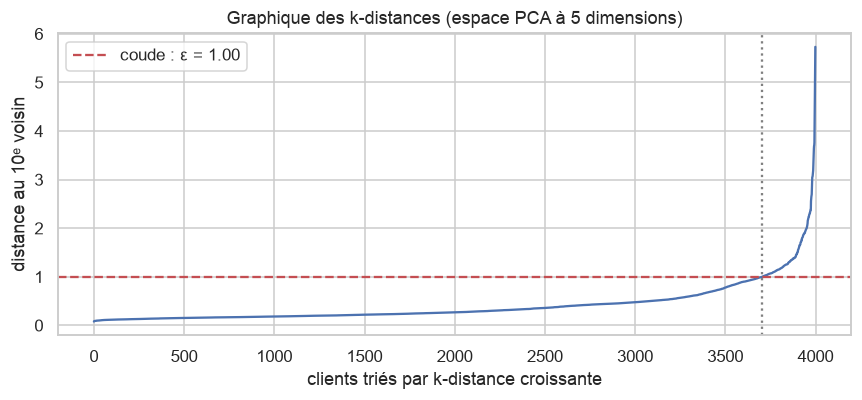

ε retenu = 0.995 ; 92.6 % des clients ont une k-distance inférieure


In [11]:
MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z5)     # le point lui-même compte, comme dans DBSCAN
kdist = np.sort(nn.kneighbors(Z5)[0][:, -1])
i_knee = knee_point(kdist)
EPS = float(kdist[i_knee])

plt.figure(figsize=(8, 3.8))
plt.plot(kdist, color="#4C72B0")
plt.axhline(EPS, ls="--", color="#C44E52", label=f"coude : ε = {EPS:.2f}")
plt.axvline(i_knee, ls=":", color="grey")
plt.xlabel("clients triés par k-distance croissante"); plt.ylabel(f"distance au {MIN_SAMPLES}ᵉ voisin")
plt.title("Graphique des k-distances (espace PCA à 5 dimensions)"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "03_k_distances.png", bbox_inches="tight"); plt.show()
print(f"ε retenu = {EPS:.3f} ; {100 * i_knee / n:.1f} % des clients ont une k-distance inférieure")

## B.3 Résultat : points cœur, bordure et bruit

In [12]:
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Z5)
lab_db = db.labels_
partitions["dbscan"] = lab_db

status = np.full(n, "bordure", dtype=object)
status[db.core_sample_indices_] = "cœur"
status[lab_db == -1] = "bruit"
n_clusters = lab_db.max() + 1
print(f"Nombre de clusters trouvés : {n_clusters}")
print(pd.Series(status).value_counts().rename("nb de clients").to_frame()
        .assign(pourcentage=lambda t: (100 * t["nb de clients"] / n).round(1)))
print("\nTailles des clusters :", sorted(np.bincount(lab_db[lab_db >= 0]), reverse=True))

Nombre de clusters trouvés : 8
         nb de clients  pourcentage
cœur              3703         92.6
bruit              150          3.8
bordure            147          3.7

Tailles des clusters : [np.int64(3264), np.int64(358), np.int64(113), np.int64(67), np.int64(15), np.int64(13), np.int64(10), np.int64(10)]


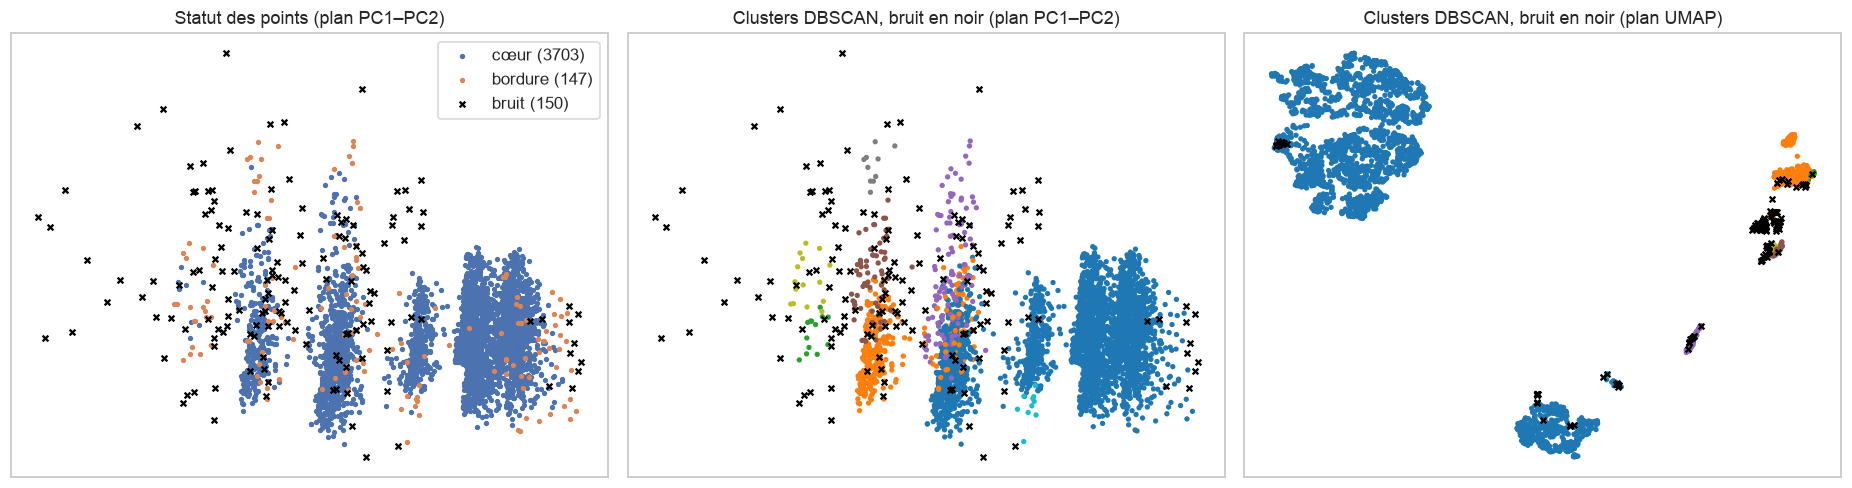

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
pal = {"cœur": "#4C72B0", "bordure": "#DD8452", "bruit": "black"}
for s in ["cœur", "bordure", "bruit"]:
    m = status == s
    axes[0].scatter(Z5[m, 0], Z5[m, 1], s=6 if s != "bruit" else 14, c=pal[s], label=f"{s} ({m.sum()})",
                    marker="o" if s != "bruit" else "x")
axes[0].set_title("Statut des points (plan PC1–PC2)"); axes[0].legend()
for ax, (Z, name) in zip(axes[1:], [(Z5[:, :2], "plan PC1–PC2"), (emb["umap"], "plan UMAP")]):
    m = lab_db >= 0
    ax.scatter(Z[m, 0], Z[m, 1], c=lab_db[m], s=6, cmap="tab10")
    ax.scatter(Z[~m, 0], Z[~m, 1], c="black", s=14, marker="x")
    ax.set_title(f"Clusters DBSCAN, bruit en noir ({name})")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "03_dbscan.png", bbox_inches="tight"); plt.show()

In [14]:
# Sensibilité aux paramètres
sens = []
for eps in [0.6, 0.8, EPS, 1.2, 1.5]:
    for ms in [5, 10, 20]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z5)
        sizes = np.bincount(l[l >= 0]) if (l >= 0).any() else np.array([0])
        sens.append({"ε": round(eps, 2), "min_samples": ms, "nb clusters": int(l.max() + 1),
                     "bruit (%)": round(100 * (l == -1).mean(), 1),
                     "plus grand cluster (%)": round(100 * sizes.max() / n, 1)})
sens = pd.DataFrame(sens)
sens.to_csv(TAB / "03_dbscan_sensibilite.csv", index=False)
sens.pivot(index="ε", columns="min_samples", values=["nb clusters", "bruit (%)", "plus grand cluster (%)"])

nb clusters            bruit (%)              \
min_samples          5     10   20        5     10    20   
ε                                                          
0.6                23.0  11.0  6.0       7.7  12.6  18.4   
0.8                19.0   7.0  8.0       4.2   9.0  12.0   
1.0                10.0   8.0  4.0       2.1   3.8   7.8   
1.2                 9.0   6.0  4.0       1.5   2.4   4.8   
1.5                 6.0   7.0  2.0       0.9   1.4   3.5   

            plus grand cluster (%)              
min_samples                     5     10    20  
ε                                               
0.6                           30.4  30.3  29.4  
0.8                           64.9  63.8  54.6  
1.0                           84.9  81.6  79.3  
1.2                           85.0  84.9  81.4  
1.5                           85.3  85.1  85.0

**Lecture.**
- DBSCAN trouve 8 clusters, dont **un très grand** (82 % des clients), quelques petits îlots denses et 3,8 % de bruit.
- Le résultat dépend fortement de ε : plus petit, il émiette les données en nombreux îlots avec beaucoup de bruit ; plus grand, tout fusionne en un bloc.
- Conclusion : dans cet espace, la clientèle forme une **masse continue**, sans « vallées » vides entre des groupes. DBSCAN n'est donc pas l'outil adapté pour **segmenter** cette clientèle. Il est en revanche très utile pour **repérer les clients atypiques**.

## B.4 Qui sont les points de bruit ? (bonus : détection d'anomalies)

In [15]:
noise = lab_db == -1
prof = pd.DataFrame({
    "bruit": X_mixed[noise][pp.ACTIVE_NUM].mean(),
    "autres clients": X_mixed[~noise][pp.ACTIVE_NUM].mean()}).round(2)
prof.loc["% contacted_before = yes"] = [100 * (X_mixed[noise]["contacted_before"] == "yes").mean(),
                                        100 * (X_mixed[~noise]["contacted_before"] == "yes").mean()]
prof.loc["% poutcome = success"] = [100 * (X_mixed[noise]["poutcome"] == "success").mean(),
                                    100 * (X_mixed[~noise]["poutcome"] == "success").mean()]
prof.loc["% job = retired ou student"] = [100 * X_mixed[noise]["job"].isin(["retired", "student"]).mean(),
                                          100 * X_mixed[~noise]["job"].isin(["retired", "student"]).mean()]
prof.loc["nb de clients"] = [noise.sum(), (~noise).sum()]
prof.round(2)

,bruit,autres clients
age,49.28,39.84
campaign,3.46,2.40
previous,1.55,0.13
cons.price.idx,93.63,93.56
cons.conf.idx,-39.29,-40.54
euribor3m,1.18,3.72
% contacted_before = yes,42.00,2.00
% poutcome = success,36.67,1.95
% job = retired ou student,34.00,5.45
nb de clients,150.00,3850.00


Les points de bruit ne sont pas des erreurs de saisie. Ce sont des clients au **profil rare** : plus âgés (49 ans en moyenne contre 40), déjà démarchés lors de campagnes précédentes (42 % contre 2 %), bien plus souvent retraités ou étudiants (34 % contre 5 %). Pour la banque, ce sont des profils à traiter à part, pas à supprimer.

# Partie C — Limites de K-means face à DBSCAN

## C.1 Démonstration sur un cas d'école
Deux croissants imbriqués et quelques points isolés : des clusters **non convexes**.

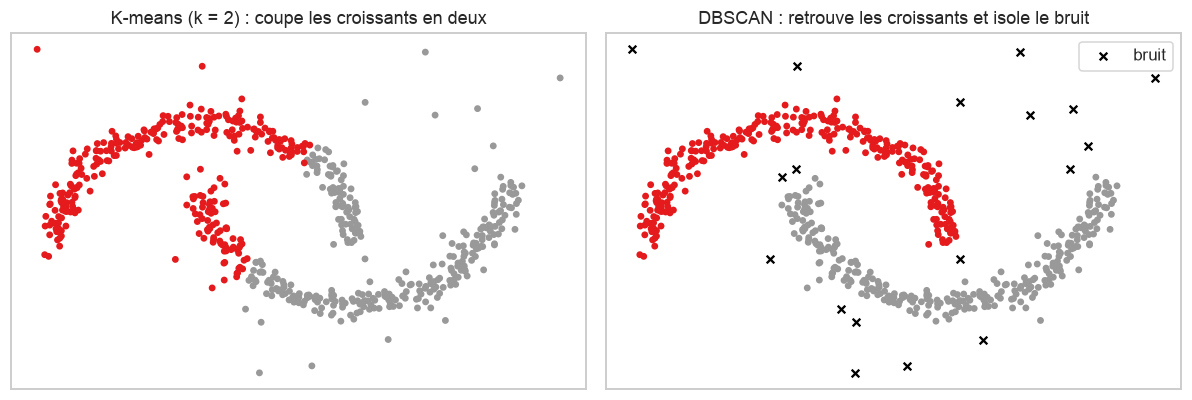

In [16]:
Xm, _ = make_moons(n_samples=600, noise=0.06, random_state=SEED)
rng = np.random.default_rng(SEED)
Xm = np.vstack([Xm, rng.uniform([-1.5, -1.2], [2.5, 1.7], size=(25, 2))])     # points isolés ajoutés
lab_km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Xm)
lab_d = DBSCAN(eps=0.15, min_samples=5).fit_predict(Xm)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(Xm[:, 0], Xm[:, 1], c=lab_km, s=12, cmap="Set1"); axes[0].set_title("K-means (k = 2) : coupe les croissants en deux")
m = lab_d >= 0
axes[1].scatter(Xm[m, 0], Xm[m, 1], c=lab_d[m], s=12, cmap="Set1")
axes[1].scatter(Xm[~m, 0], Xm[~m, 1], c="black", marker="x", s=25, label="bruit")
axes[1].set_title("DBSCAN : retrouve les croissants et isole le bruit"); axes[1].legend()
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "03_kmeans_vs_dbscan_demo.png", bbox_inches="tight"); plt.show()

K-means affecte chaque point au **centre le plus proche** : ses frontières sont des droites (cellules de Voronoï), ses clusters sont forcément convexes. Il coupe donc les croissants en deux et il range les points isolés dans un cluster, ce qui déplace les centres. DBSCAN suit la densité : il retrouve les deux formes et écarte le bruit.

## C.2 Et sur nos données bancaires ?

                  count  mean   50%   max
statut DBSCAN                            
bruit             150.0  4.26  3.98  10.6
dans un cluster  3850.0  2.35  2.25   5.8


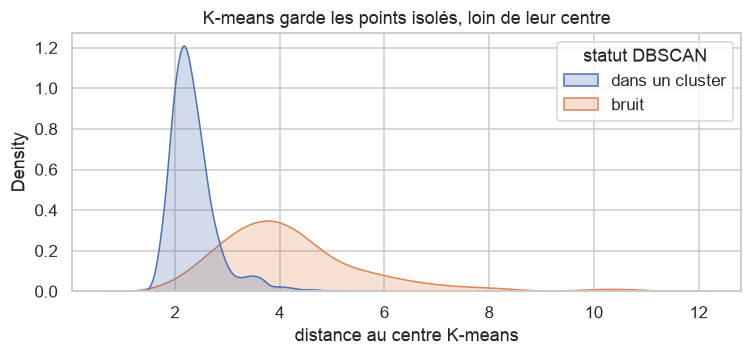

In [17]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_a)
dist_centre = np.linalg.norm(X_a.values - km4.cluster_centers_[km4.labels_], axis=1)
cmp = pd.DataFrame({"statut DBSCAN": np.where(noise, "bruit", "dans un cluster"), "distance au centre K-means": dist_centre})
print(cmp.groupby("statut DBSCAN")["distance au centre K-means"].describe()[["count", "mean", "50%", "max"]].round(2))

plt.figure(figsize=(7, 3.4))
sns.kdeplot(data=cmp, x="distance au centre K-means", hue="statut DBSCAN", common_norm=False, fill=True)
plt.title("K-means garde les points isolés, loin de leur centre")
plt.tight_layout(); plt.savefig(FIG / "03_distance_centres.png", bbox_inches="tight"); plt.show()

**Discussion.**

| | K-means | DBSCAN |
|---|---|---|
| Nombre de clusters | à fixer | trouvé automatiquement |
| Forme des clusters | convexe, sphérique | quelconque |
| Points isolés | **forcés** dans un cluster ; ils tirent les centres vers eux | étiquetés « bruit » |
| Densités différentes | sans objet | **difficulté** : un seul ε pour tout l'espace |
| Résultat sur nos données | groupes équilibrés et exploitables | 1 cluster géant + îlots + bruit |

- Les clients que DBSCAN classe en bruit sont, pour K-means, des points **presque deux fois plus éloignés de leur centre** que les autres (4,3 contre 2,4 en moyenne) : K-means les a rangés de force dans un segment qui leur ressemble peu.
- Inversement, DBSCAN ne sait pas découper une masse continue : il ne fournit pas de segmentation utilisable ici.
- Les deux méthodes sont donc **complémentaires** : K-means (ou Ward) pour segmenter, DBSCAN pour signaler les clients atypiques.

## Bilan du Jour 3
1. **CAH** : le lien change tout. *Single* produit un effet de chaîne, *average* et *complete* isolent des atypiques, **Ward** donne des groupes équilibrés. L'arbre suggère k = 2 puis k = 5 ; la silhouette préfère k = 2 puis k = 4. Décision au Jour 4.
2. **CAH sur Gower** : fait ressortir des niches liées à l'historique de contact.
3. **DBSCAN** : ε réglé par le coude des k-distances, `min_samples` = 10. Un cluster dominant, quelques îlots, du bruit interprétable comme clients atypiques.
4. Leçon de méthode : une **silhouette élevée ne suffit pas** ; il faut toujours vérifier la taille des clusters.

In [18]:
for m in ["single", "complete", "average"]:
    for k in range(2, 7):                    # mêmes valeurs de k que les autres méthodes (Jour 4)
        partitions[f"cah_{m}_k{k}"] = fcluster(links[m], t=k, criterion="maxclust") - 1
partitions.to_csv(LAB / "partitions_j3.csv")
print("Partitions enregistrées :", list(partitions.columns))

Partitions enregistrées : ['ward_k2', 'ward_k3', 'ward_k4', 'ward_k5', 'ward_k6', 'cah_gower_k2', 'cah_gower_k3', 'cah_gower_k4', 'cah_gower_k5', 'cah_gower_k6', 'dbscan', 'cah_single_k2', 'cah_single_k3', 'cah_single_k4', 'cah_single_k5', 'cah_single_k6', 'cah_complete_k2', 'cah_complete_k3', 'cah_complete_k4', 'cah_complete_k5', 'cah_complete_k6', 'cah_average_k2', 'cah_average_k3', 'cah_average_k4', 'cah_average_k5', 'cah_average_k6']
